# Phase 9: Hybrid Model Evaluation

## Objective
Evaluate the Hybrid Recommendation System and compare its
performance against Content-Based and Collaborative Filtering.

## Evaluation Metrics
- Precision@10
- Recall@10
- RMSE
- MAE

## Evaluation Strategy
Use the same training and testing data split for all models
to ensure a fair comparison.


In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
from scipy.sparse import csr_matrix, lil_matrix

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
BASE_DIR = Path.cwd().parent

DATA_DIR = BASE_DIR / "data" / "processed"
FEATURE_DIR = DATA_DIR / "features"

print("Project directory:", BASE_DIR)

Project directory: /home/shahzad-mustafa/Desktop/MovieRecommendationSystem


In [3]:
movies = pd.read_csv(DATA_DIR / "movies_clean.csv")
ratings = pd.read_csv(DATA_DIR / "ratings_clean.csv")

genre_features = pd.read_csv(
    FEATURE_DIR / "movie_genre_features.csv",
    index_col="MovieID"
)

movies["MovieID"] = movies["MovieID"].astype(int)
ratings["MovieID"] = ratings["MovieID"].astype(int)
ratings["UserID"] = ratings["UserID"].astype(int)

genre_features.index = genre_features.index.astype(int)

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Genre features:", genre_features.shape)

Movies: (3883, 3)
Ratings: (1000209, 5)
Genre features: (3883, 18)


In [4]:
# Step 1: Split ratings into training and testing datasets

train_parts = []
test_parts = []

for user_id, group in ratings.groupby("UserID"):
    group = group.sample(frac=1, random_state=42)

    test_size = max(1, int(len(group) * 0.2))

    test_parts.append(group.iloc[:test_size])
    train_parts.append(group.iloc[test_size:])

train_ratings = pd.concat(train_parts).reset_index(drop=True)
test_ratings = pd.concat(test_parts).reset_index(drop=True)


# Step 2: Display split information

print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)

print("Training users:", train_ratings["UserID"].nunique())
print("Testing users:", test_ratings["UserID"].nunique())

print(
    "Training percentage:",
    round(len(train_ratings) / len(ratings) * 100, 2),
    "%"
)

print(
    "Testing percentage:",
    round(len(test_ratings) / len(ratings) * 100, 2),
    "%"
)


# Step 3: Identify positive ratings

train_positive = train_ratings[
    train_ratings["Rating"] >= 4
]

test_positive = test_ratings[
    test_ratings["Rating"] >= 4
]

print("Positive training ratings:", len(train_positive))
print("Positive testing ratings:", len(test_positive))

Training ratings: (802553, 5)
Testing ratings: (197656, 5)
Training users: 6040
Testing users: 6040
Training percentage: 80.24 %
Testing percentage: 19.76 %
Positive training ratings: 461478
Positive testing ratings: 113803


In [5]:
# Create a genre profile for each user using training ratings only

train_positive = train_ratings[
    train_ratings["Rating"] >= 4
]

user_profiles = {}

for user_id, group in train_positive.groupby("UserID"):

    liked_movie_ids = group["MovieID"]

    available_movies = genre_features.index.intersection(
        liked_movie_ids
    )

    if len(available_movies) == 0:
        continue

    user_profiles[user_id] = genre_features.loc[
        available_movies
    ].mean(axis=0)

print("Number of user profiles:", len(user_profiles))

Number of user profiles: 6038


In [6]:
test_relevant = (
    test_positive.groupby("UserID")["MovieID"]
    .apply(set)
    .to_dict()
)

print("Users with relevant test movies:", len(test_relevant))

Users with relevant test movies: 6014


In [7]:
train_watched = (
    train_ratings.groupby("UserID")["MovieID"]
    .apply(set)
    .to_dict()
)

print("Users with training history:", len(train_watched))

Users with training history: 6040


In [8]:
candidate_movie_ids = np.array(
    sorted(
        set(train_ratings["MovieID"])
        .intersection(genre_features.index)
    )
)

print("Candidate movies:", len(candidate_movie_ids))

Candidate movies: 3680


In [9]:
train_user_movie_matrix = train_ratings.pivot(
    index="UserID",
    columns="MovieID",
    values="Rating"
)

print("Matrix shape:", train_user_movie_matrix.shape)
print("Missing values:", train_user_movie_matrix.isna().sum().sum())

Matrix shape: (6040, 3680)
Missing values: 21424647


In [10]:
train_user_means = train_user_movie_matrix.mean(axis=1)

centered_train_matrix = (
    train_user_movie_matrix
    .sub(train_user_means, axis=0)
    .fillna(0)
)

print("User means:", train_user_means.shape)
print("Centered matrix:", centered_train_matrix.shape)

User means: (6040,)
Centered matrix: (6040, 3680)


In [11]:
centered_train_sparse = csr_matrix(
    centered_train_matrix.to_numpy(dtype=np.float32)
)

rating_presence = csr_matrix(
    train_user_movie_matrix.notna().to_numpy(dtype=np.float32)
)

print("Centered sparse matrix:", centered_train_sparse.shape)
print("Rating presence matrix:", rating_presence.shape)

Centered sparse matrix: (6040, 3680)
Rating presence matrix: (6040, 3680)


In [12]:
train_similarity_matrix = cosine_similarity(
    centered_train_sparse,
    dense_output=False
).tocsr()

print("Similarity matrix:", train_similarity_matrix.shape)

Similarity matrix: (6040, 6040)


In [13]:
top20_train_similarity = lil_matrix(
    train_similarity_matrix.shape,
    dtype=np.float32
)

for user_index in range(train_similarity_matrix.shape[0]):

    similarity_row = train_similarity_matrix.getrow(user_index)

    neighbor_indices = similarity_row.indices
    neighbor_scores = similarity_row.data

    valid_mask = (
        (neighbor_indices != user_index) &
        (neighbor_scores > 0)
    )

    neighbor_indices = neighbor_indices[valid_mask]
    neighbor_scores = neighbor_scores[valid_mask]

    if len(neighbor_scores) > 20:
        top_indices = np.argsort(neighbor_scores)[-20:]

        neighbor_indices = neighbor_indices[top_indices]
        neighbor_scores = neighbor_scores[top_indices]

    top20_train_similarity[
        user_index, neighbor_indices
    ] = neighbor_scores

top20_train_similarity = top20_train_similarity.tocsr()

print("Non-zero neighbor similarities:", top20_train_similarity.nnz)

Non-zero neighbor similarities: 120800


In [14]:
weighted_deviations_train = (
    top20_train_similarity.dot(centered_train_sparse)
).tocsr()

similarity_weights_train = (
    top20_train_similarity.dot(rating_presence)
).tocsr()

print("Weighted deviations:", weighted_deviations_train.shape)
print("Similarity weights:", similarity_weights_train.shape)

Weighted deviations: (6040, 3680)
Similarity weights: (6040, 3680)


In [15]:
candidate_column_indices = train_user_movie_matrix.columns.get_indexer(
    candidate_movie_ids
)

print("Total candidate movies:", len(candidate_movie_ids))
print("Movies found in training matrix:", (candidate_column_indices >= 0).sum())
print("Missing movie columns:", (candidate_column_indices < 0).sum())

Total candidate movies: 3680
Movies found in training matrix: 3680
Missing movie columns: 0


In [16]:
def get_user_candidate_scores(user_id, alpha=0.5):

    if user_id not in user_profiles:
        return None

    if user_id not in train_user_movie_matrix.index:
        return None

    # Find the user's row position
    user_index = train_user_movie_matrix.index.get_loc(user_id)

    # Get collaborative filtering values
    numerator = weighted_deviations_train.getrow(user_index).toarray().ravel()
    denominator = similarity_weights_train.getrow(user_index).toarray().ravel()

    # Keep only movies with collaborative evidence
    valid_mask = denominator[candidate_column_indices] > 0

    eligible_movie_ids = candidate_movie_ids[valid_mask]
    eligible_columns = candidate_column_indices[valid_mask]

    # Remove movies already watched by the user
    watched = train_watched.get(user_id, set())

    unseen_mask = ~np.isin(eligible_movie_ids, list(watched))

    eligible_movie_ids = eligible_movie_ids[unseen_mask]
    eligible_columns = eligible_columns[unseen_mask]

    if len(eligible_movie_ids) == 0:
        return None

    # Calculate content-based scores
    user_profile_array = user_profiles[user_id].values.reshape(1, -1)

    content_scores = cosine_similarity(
        user_profile_array,
        genre_features.loc[eligible_movie_ids]
    )[0]

    # Calculate collaborative filtering predictions
    predicted_ratings = (
        train_user_means.loc[user_id]
        + numerator[eligible_columns] / denominator[eligible_columns]
    )

    predicted_ratings = np.clip(predicted_ratings, 1, 5)

    # Normalize collaborative scores to 0-1
    collaborative_scores = (predicted_ratings - 1) / 4

    # Calculate hybrid scores
    hybrid_scores = (
        alpha * content_scores
        + (1 - alpha) * collaborative_scores
    )

    # Create results DataFrame
    results = pd.DataFrame({
        "MovieID": eligible_movie_ids,
        "ContentScore": content_scores,
        "CollaborativeScore": collaborative_scores,
        "HybridScore": hybrid_scores
    })

    # Add movie details
    results = results.merge(
        movies[["MovieID", "Title", "Genres"]],
        on="MovieID",
        how="left"
    )

    return results.sort_values(
        "HybridScore",
        ascending=False
    ).reset_index(drop=True)

In [17]:
test_scores = get_user_candidate_scores(user_id=1, alpha=0.5)

test_scores.head(10)

,MovieID,ContentScore,CollaborativeScore,HybridScore,Title,Genres
0,1012,0.769800,1.000000,0.884900,Old Yeller (1957),Children's|Drama
1,2102,0.765466,0.992350,0.878908,Steamboat Willie (1940),Animation|Children's|Comedy|Musical
2,1014,0.785674,0.950185,0.867930,Pollyanna (1960),Children's|Comedy|Drama
3,1032,0.726749,0.992350,0.859549,Alice in Wonderland (1951),Animation|Children's|Musical
4,364,0.726749,0.982449,0.854599,"Lion King, The (1994)",Animation|Children's|Musical
5,2096,0.726749,0.964901,0.845825,Sleeping Beauty (1959),Animation|Children's|Musical
6,2141,0.667823,1.000000,0.833912,"American Tail, An (1986)",Animation|Children's|Comedy
7,2087,0.663403,1.000000,0.831702,Peter Pan (1953),Animation|Children's|Fantasy|Musical
8,2080,0.715082,0.927315,0.821199,Lady and the Tramp (1955),Animation|Children's|Comedy|Musical|Romance
9,3159,0.726749,0.910186,0.818467,Fantasia 2000 (1999),Animation|Children's|Musical


In [18]:
def evaluate_all_models(alpha=0.5, k=10):

    content_precisions = []
    content_recalls = []

    collaborative_precisions = []
    collaborative_recalls = []

    hybrid_precisions = []
    hybrid_recalls = []

    evaluated_users = 0

    for user_id, relevant_movies in test_relevant.items():

        scores = get_user_candidate_scores(
            user_id=user_id,
            alpha=alpha
        )

        if scores is None or len(scores) == 0:
            continue

        # Relevant test movies available in the common candidate set
        relevant = set(relevant_movies).intersection(
            set(scores["MovieID"])
        )

        if len(relevant) == 0:
            continue

        evaluated_users += 1

        # Evaluate each model using the same candidate movies
        model_columns = {
            "content": "ContentScore",
            "collaborative": "CollaborativeScore",
            "hybrid": "HybridScore"
        }

        for model, score_column in model_columns.items():

            recommendations = scores.nlargest(
                k,
                score_column
            )

            recommended_ids = set(recommendations["MovieID"])

            hits = len(recommended_ids.intersection(relevant))

            precision = hits / min(k, len(scores))
            recall = hits / len(relevant)

            if model == "content":
                content_precisions.append(precision)
                content_recalls.append(recall)

            elif model == "collaborative":
                collaborative_precisions.append(precision)
                collaborative_recalls.append(recall)

            else:
                hybrid_precisions.append(precision)
                hybrid_recalls.append(recall)

    return {
        "Evaluated Users": evaluated_users,

        "Content-Based Precision@10": np.mean(content_precisions),
        "Content-Based Recall@10": np.mean(content_recalls),

        "Collaborative Precision@10": np.mean(collaborative_precisions),
        "Collaborative Recall@10": np.mean(collaborative_recalls),

        "Hybrid Precision@10": np.mean(hybrid_precisions),
        "Hybrid Recall@10": np.mean(hybrid_recalls)
    }

In [19]:
hybrid_evaluation_results = evaluate_all_models(
    alpha=0.5,
    k=10
)

hybrid_evaluation_results

{'Evaluated Users': 5955,
 'Content-Based Precision@10': np.float64(0.05452560873215786),
 'Content-Based Recall@10': np.float64(0.05058961112530307),
 'Collaborative Precision@10': np.float64(0.030596137699412263),
 'Collaborative Recall@10': np.float64(0.02441152263677252),
 'Hybrid Precision@10': np.float64(0.062485306465155335),
 'Hybrid Recall@10': np.float64(0.05644575689773003)}

In [20]:
alpha_values = [0.3, 0.5, 0.7]

weight_results = []

for alpha in alpha_values:

    results = evaluate_all_models(
        alpha=alpha,
        k=10
    )

    results["Alpha"] = alpha

    weight_results.append(results)

weight_comparison = pd.DataFrame(weight_results)

weight_comparison

,Evaluated Users,Content-Based Precision@10,Content-Based Recall@10,Collaborative Precision@10,Collaborative Recall@10,Hybrid Precision@10,Hybrid Recall@10,Alpha
0,5955,0.054458,0.050722,0.030327,0.024309,0.050193,0.044819,0.3
1,5955,0.054526,0.050590,0.030596,0.024412,0.062485,0.056446,0.5
2,5955,0.054593,0.050609,0.030714,0.024490,0.067893,0.060758,0.7


In [21]:
weight_comparison[
    [
        "Alpha",
        "Hybrid Precision@10",
        "Hybrid Recall@10"
    ]
].sort_values(
    "Hybrid Precision@10",
    ascending=False
)

,Alpha,Hybrid Precision@10,Hybrid Recall@10
2,0.7,0.067893,0.060758
1,0.5,0.062485,0.056446
0,0.3,0.050193,0.044819


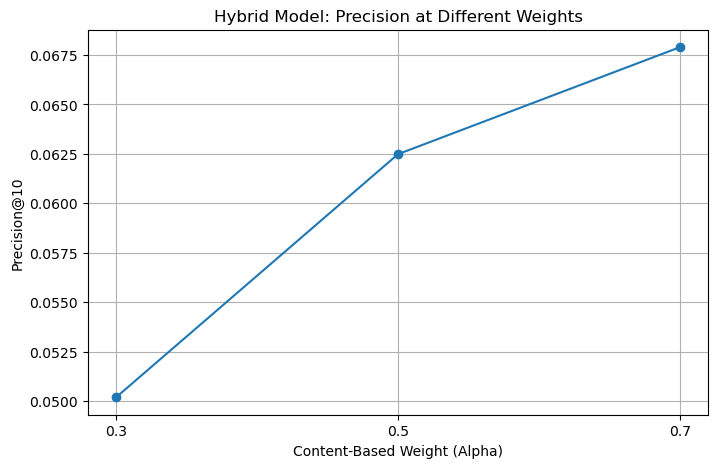

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    weight_comparison["Alpha"],
    weight_comparison["Hybrid Precision@10"],
    marker="o"
)

plt.xlabel("Content-Based Weight (Alpha)")
plt.ylabel("Precision@10")
plt.title("Hybrid Model: Precision at Different Weights")
plt.xticks([0.3, 0.5, 0.7])
plt.grid(True)
plt.show()

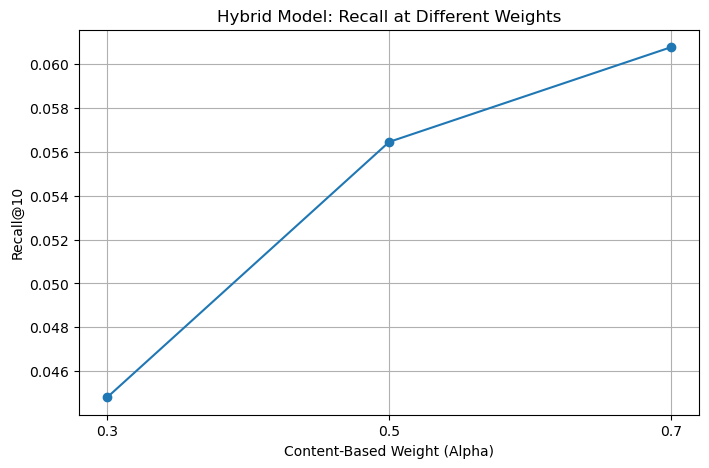

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    weight_comparison["Alpha"],
    weight_comparison["Hybrid Recall@10"],
    marker="o"
)

plt.xlabel("Content-Based Weight (Alpha)")
plt.ylabel("Recall@10")
plt.title("Hybrid Model: Recall at Different Weights")
plt.xticks([0.3, 0.5, 0.7])
plt.grid(True)
plt.show()

In [24]:
weight_comparison[
    [
        "Alpha",
        "Evaluated Users",
        "Content-Based Precision@10",
        "Collaborative Precision@10",
        "Hybrid Precision@10",
        "Content-Based Recall@10",
        "Collaborative Recall@10",
        "Hybrid Recall@10"
    ]
].round(5)

,Alpha,Evaluated Users,Content-Based Precision@10,Collaborative Precision@10,Hybrid Precision@10,Content-Based Recall@10,Collaborative Recall@10,Hybrid Recall@10
0,0.3,5955,0.05446,0.03033,0.05019,0.05072,0.02431,0.04482
1,0.5,5955,0.05453,0.03060,0.06249,0.05059,0.02441,0.05645
2,0.7,5955,0.05459,0.03071,0.06789,0.05061,0.02449,0.06076


In [25]:
from pathlib import Path

REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

weight_comparison.to_csv(
    REPORT_DIR / "hybrid_weight_comparison.csv",
    index=False
)

print("Hybrid evaluation results saved successfully.")

Hybrid evaluation results saved successfully.


In [26]:
best_configuration = weight_comparison.loc[
    weight_comparison["Hybrid Precision@10"].idxmax()
]

print("Best Alpha:", best_configuration["Alpha"])
print(
    "Best Hybrid Precision@10:",
    best_configuration["Hybrid Precision@10"]
)
print(
    "Corresponding Hybrid Recall@10:",
    best_configuration["Hybrid Recall@10"]
)

Best Alpha: 0.7
Best Hybrid Precision@10: 0.06789252728799329
Corresponding Hybrid Recall@10: 0.06075848966904477
